# 05_final.ipynb
Gộp 01, 03 và 04 lại thành một notebook duy nhất. Rửa dữ liệu train, tạo đặc trưng, huấn luyện trên toàn bộ train, rồi dự đoán test.csv và xuất kết quả ra data/results.

## 1. Import libraries và đọc dữ liệu

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import warnings
from datetime import datetime
from flaml import AutoML

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
mandatory_cols = [
    "MSSubClass", "MSZoning", "LotArea", "Street", "LotShape", "LandContour", 
    "Utilities", "LotConfig", "LandSlope", "Neighborhood", "Condition1", 
    "Condition2", "BldgType", "HouseStyle", "OverallQual", "OverallCond", 
    "YearBuilt", "YearRemodAdd", "RoofStyle", "RoofMatl", "Exterior1st", 
    "Exterior2nd", "ExterQual", "ExterCond", "Foundation", "Heating", 
    "HeatingQC", "CentralAir", "Electrical", "1stFlrSF", "2ndFlrSF", 
    "LowQualFinSF", "GrLivArea", "FullBath", "HalfBath", "Bedroom", 
    "Kitchen", "KitchenQual", "TotRmsAbvGrd", "Functional", "PavedDrive", 
    "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", 
    "MoSold", "YrSold", "SaleType", "SaleCondition"
]
missing_targets = ["", "NA", "N/A", "null", "NULL", "None", "NaN", "nan", "?"]
na_values = {col: missing_targets for col in mandatory_cols}

df = pd.read_csv("../data/raw/train.csv", keep_default_na=False, na_values=na_values)
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


Cột ID vô dụng, bỏ khỏi dataframe.

In [3]:
df = df.drop("Id", axis="columns")
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,Inside,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,FR2,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,Inside,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,Corner,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,FR2,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


## 2. Kiểm tra sai dữ liệu và kiểu dữ liệu

Đối chiếu trên Kaggle, có thể thấy cột MasVnrType có 2 dạng đại diện cho NA (Na + None). Sửa lại bằng cách chuyển hết None thành NA.

<div>
<img src="../assets/multiple_na.png" width="200"/>
</div>

In [4]:
df["MasVnrType"] = df["MasVnrType"].replace("None", "NA")
len(df[df["MasVnrType"] == "None"])

0

LotFrontage, MasVnrArea và GarageYrBlt đang là string dù là cột số, do có ô trống hoặc NA lẫn vào. Ép lại thành số, ô trống và NA sẽ thành NaN.

In [5]:
numeric_like = ["LotFrontage", "MasVnrArea", "GarageYrBlt"]
df[numeric_like] = df[numeric_like].apply(pd.to_numeric, errors="coerce")

## 3. Kiểm tra dữ liệu bị thiếu

In [6]:
all_missing = df.isna().sum()
all_missing[all_missing != 0]

LotFrontage    259
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64

Đối với Electrical, vì chỉ duy nhất một hàng thiếu và một giá trị xuất hiện đa số nên sẽ dùng giá trị đó luôn (SBrkr xuất hiện 91%).

In [7]:
df["Electrical"] = df["Electrical"].fillna("SBrkr")

GarageYrBlt điền bằng YearBuilt (GarageType vẫn cho biết nhà đó không có gara). LotFrontage và MasVnrArea điền bằng median. Median được lưu lại để dùng cho test.

In [8]:
medians = df[["LotFrontage", "MasVnrArea"]].median()
df[["LotFrontage", "MasVnrArea"]] = df[["LotFrontage", "MasVnrArea"]].fillna(medians)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"]).astype(int)

In [9]:
all_missing = df.isna().sum()
all_missing[all_missing != 0]

Series([], dtype: int64)

## 4. Kiểm tra skewness và outliers
Chỉ vẽ các cột số liên tục (diện tích, giá trị), bỏ các cột chỉ để đếm (số phòng, số xe, số lò sưởi...) và các cột là mã hoặc năm.

In [10]:
continuous_cols = [
    "LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF",
    "EnclosedPorch", "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal", "SalePrice"
]
numeric_cols = df[continuous_cols].copy()

Histogram để xem skewness.

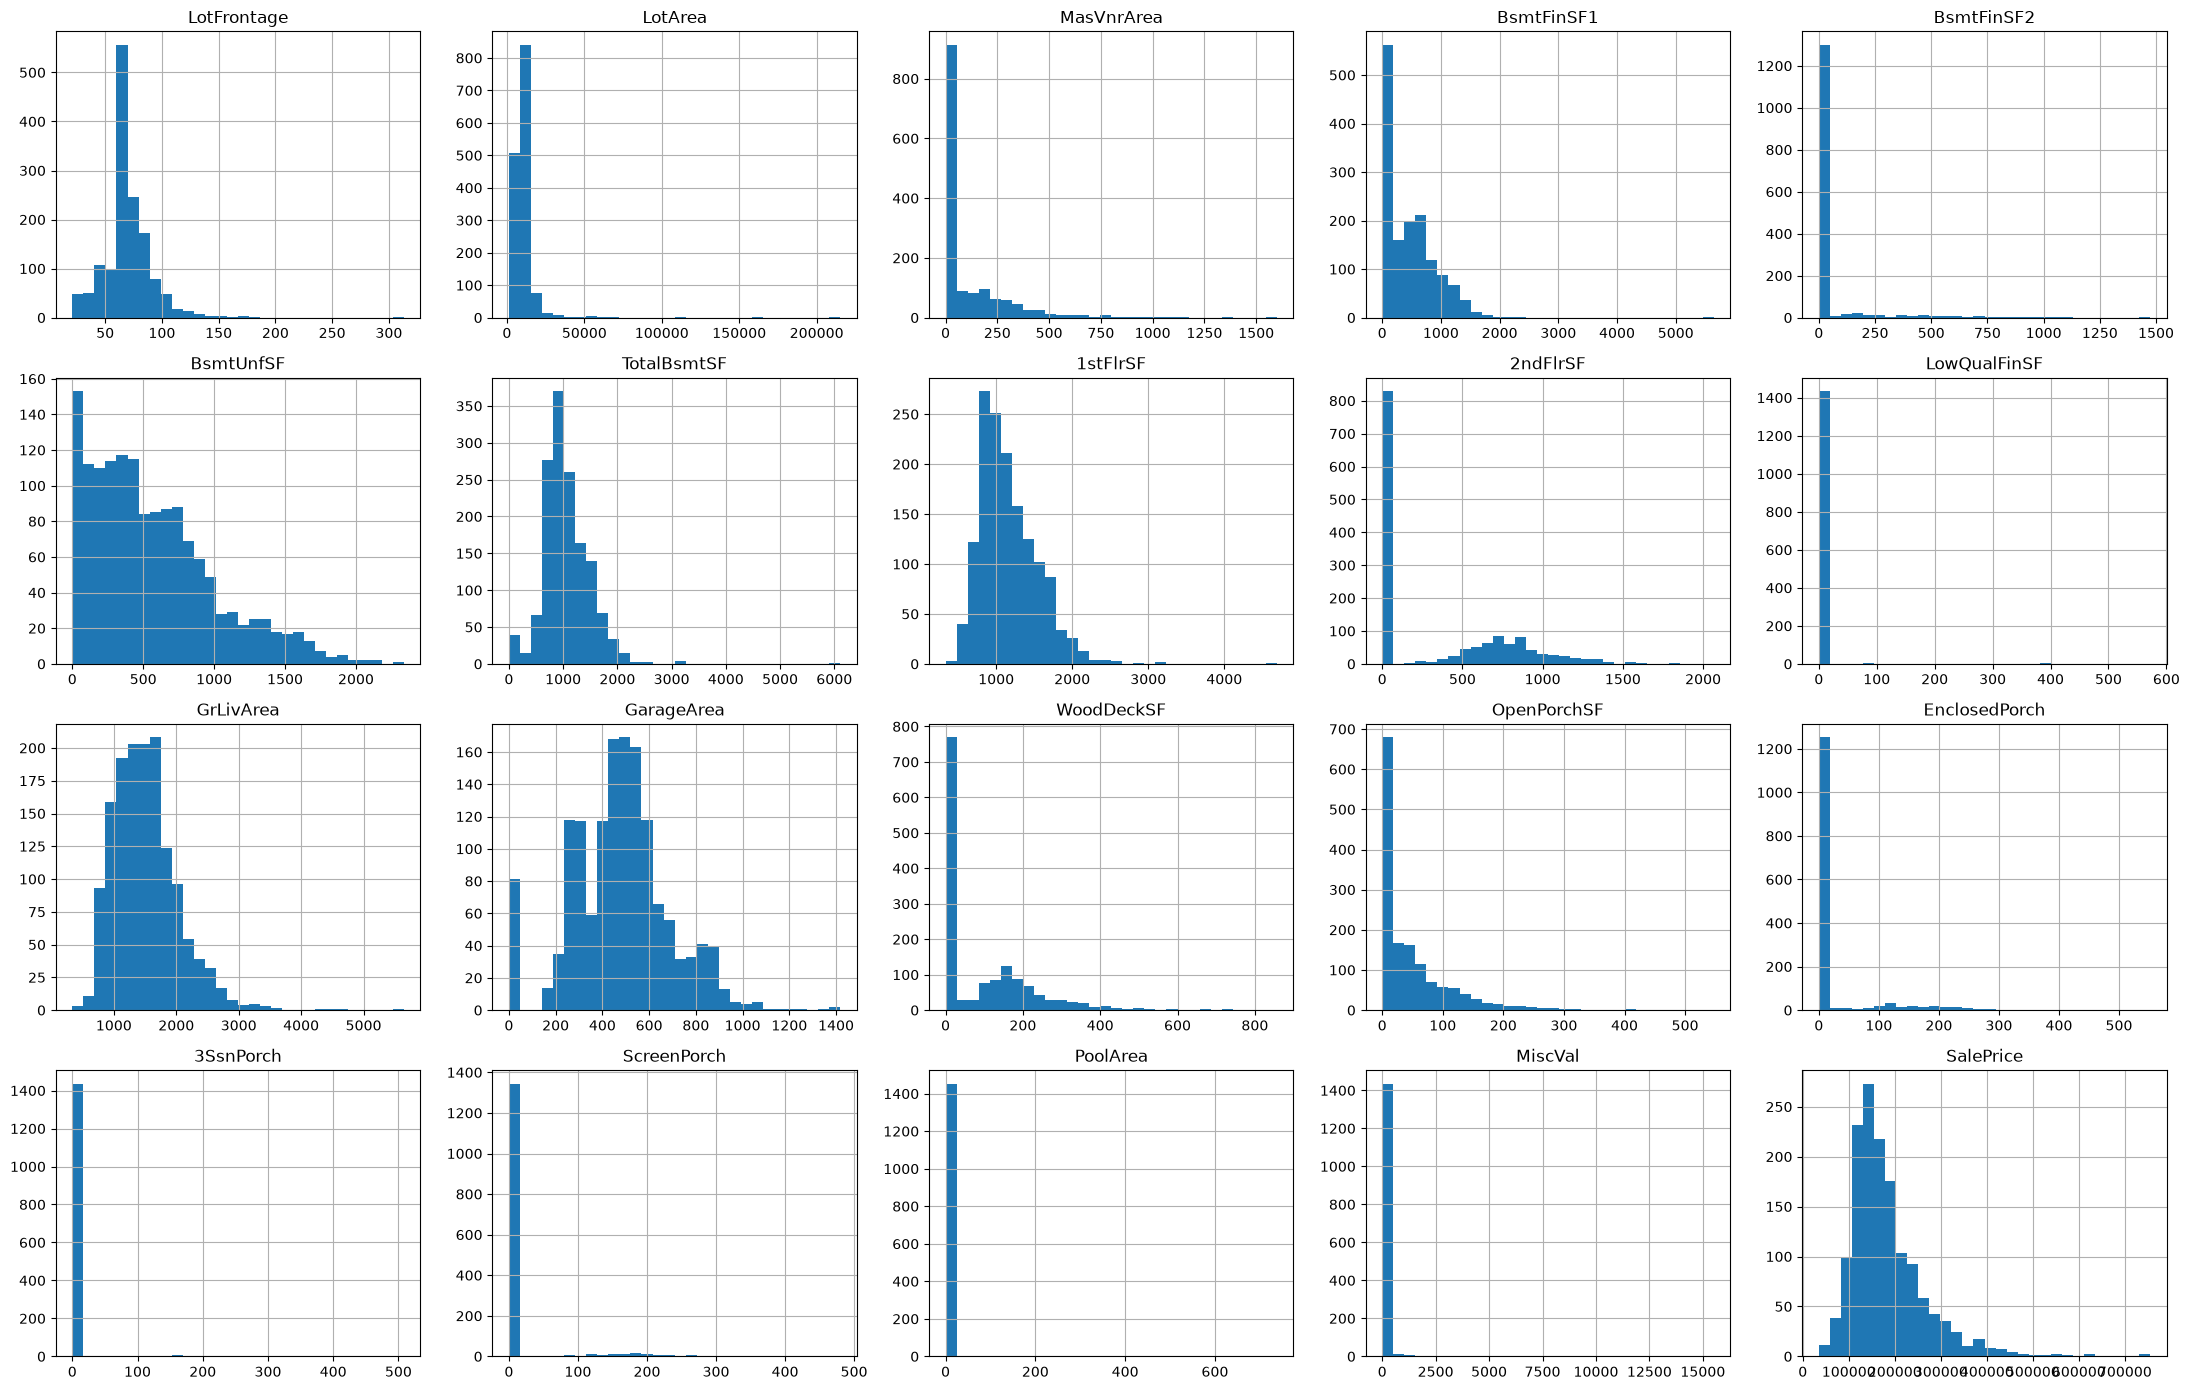

In [11]:
numeric_cols.hist(bins=30, figsize=(22, 14), layout=(4, 5))
plt.tight_layout()
plt.show()

Các cột đều lệch phải nên chuyển sang log. Nhiều cột có giá trị 0 nên dùng log1p (log của 1 + x) để không bị lỗi.

In [12]:
numeric_cols = np.log1p(numeric_cols)
df[continuous_cols] = numeric_cols

Vẽ lại histogram sau khi log.

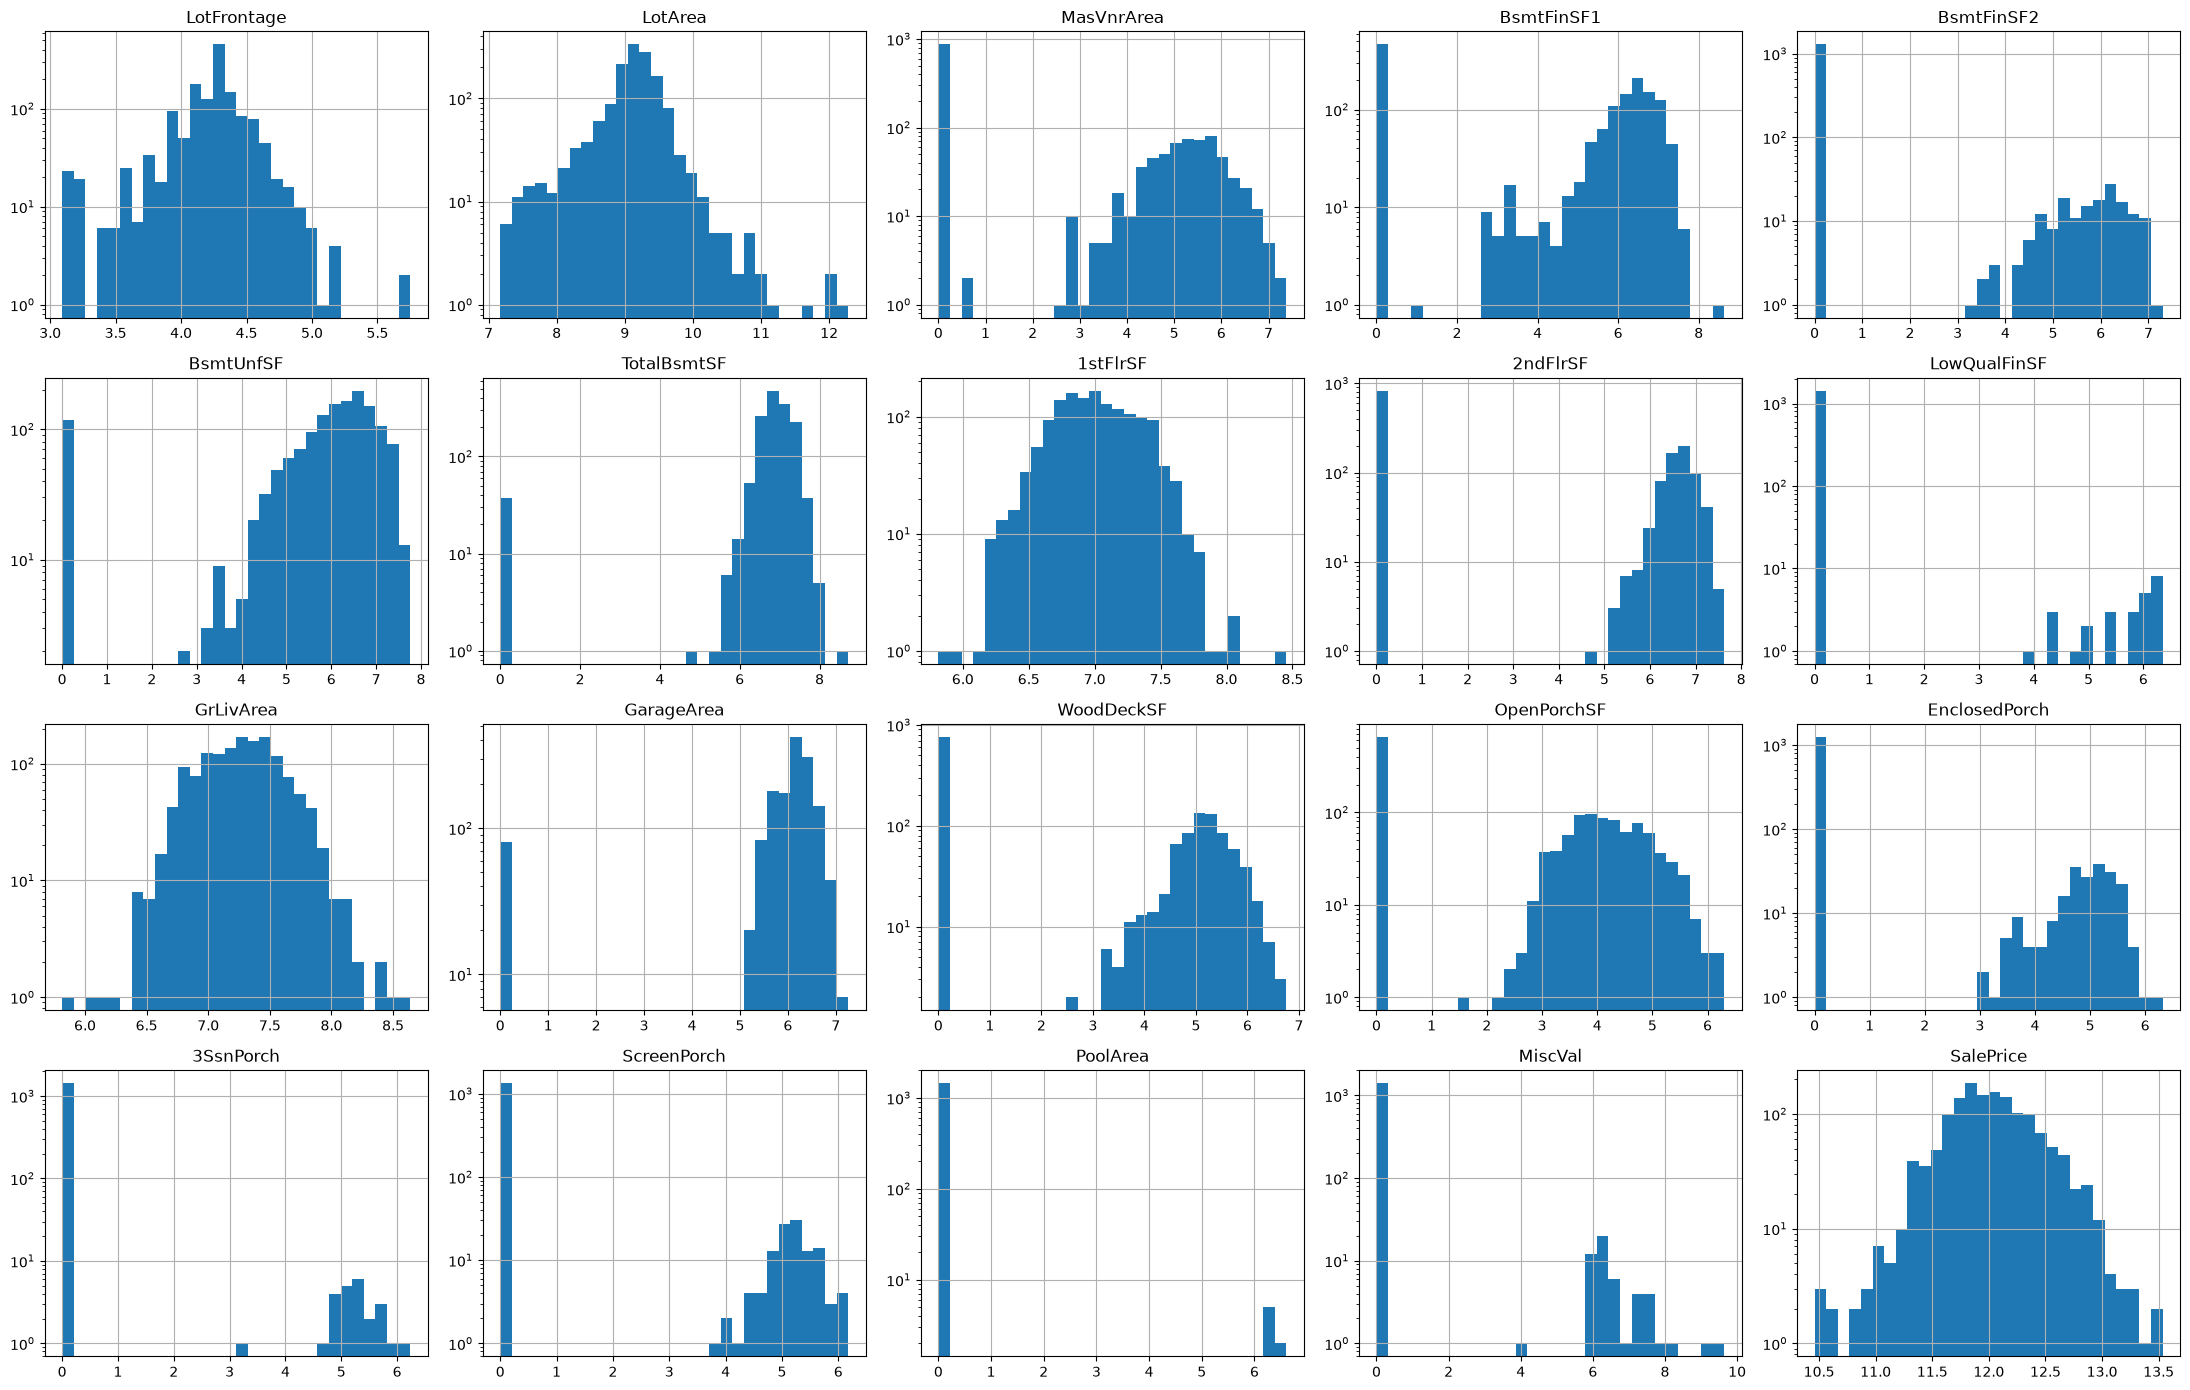

In [13]:
numeric_cols.hist(bins=30, figsize=(22, 14), layout=(4, 5), log=True)
plt.tight_layout()
plt.show()

## 5. Đưa các cột diện tích về đơn vị gốc
Các cột diện tích đã được lấy log1p ở bước 4. Để cộng dồn hoặc chia tỷ lệ chính xác, ta dùng `expm1` để đưa về đơn vị diện tích thực tế trước khi tính toán.

In [14]:
log_cols = ["LotArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]
original = np.expm1(df[log_cols]).round()

## 6. Tạo các đặc trưng mới
Tạo các cột mới tự nhiên hơn mà những người đánh giá nhà hay để ý đến.

In [15]:
df["TotalSF"] = np.log1p(original["TotalBsmtSF"] + original["1stFlrSF"] + original["2ndFlrSF"])
df["TotalPorchSF"] = np.log1p(original[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1))
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
df["AreaPerRoom"] = np.log1p(original["GrLivArea"] / df["TotRmsAbvGrd"])
df["LotCoverage"] = original["1stFlrSF"] / original["LotArea"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)

df["HasEnclosedPorch"] = (df["EnclosedPorch"] > 0).astype(int)
df["HasScreenPorch"] = (df["ScreenPorch"] > 0).astype(int)
df["HasWoodDeck"] = (df["WoodDeckSF"] > 0).astype(int)

## 7. Đo lường tương quan thực tế
Tính toán và ghi nhận mức độ tương quan của từng đặc trưng vừa tạo với SalePrice.

In [16]:
new_features = [
    "TotalSF", "TotalPorchSF", "TotalBath", "AreaPerRoom", "LotCoverage",
    "HouseAge", "RemodAge", "IsRemodeled", "HasEnclosedPorch", "HasScreenPorch", "HasWoodDeck"
]
print(df[new_features + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False))

SalePrice           1.000000
TotalSF             0.807140
TotalBath           0.673011
AreaPerRoom         0.576017
HasWoodDeck         0.320349
TotalPorchSF        0.309608
HasScreenPorch      0.099436
LotCoverage        -0.023396
IsRemodeled        -0.073761
HasEnclosedPorch   -0.216559
RemodAge           -0.568136
HouseAge           -0.587290
Name: SalePrice, dtype: float64


## 8. Chọn lọc đặc trưng và loại bỏ các cột vô dụng
Chọn lọc dựa trên kết quả đo lường thực nghiệm ở bước 7 và phân tích SHAP.

In [17]:
drop_cols = [
    "LotCoverage", "IsRemodeled",
    "PoolArea", "PoolQC", "MiscVal", "MiscFeature", "3SsnPorch",
    "LowQualFinSF", "BsmtFinSF2", "BsmtHalfBath", "KitchenAbvGr",
    "Functional", "GarageQual", "GarageCond", "BldgType", "RoofMatl",
    "Utilities", "LandContour", "Street", "Alley", "Condition2",
    "Condition1", "LandSlope", "Heating", "BsmtCond", "MSZoning",
    "LotShape", "ExterCond", "MasVnrType", "Electrical", "BsmtFinType2",
    "RoofStyle", "PavedDrive", "Fence", "YrSold", "MoSold", "SaleType"
]
df = df.drop(columns=drop_cols)

## 9. Phân phối sau khi tinh giản
Vẽ biểu đồ histogram cho các đặc trưng số mới.

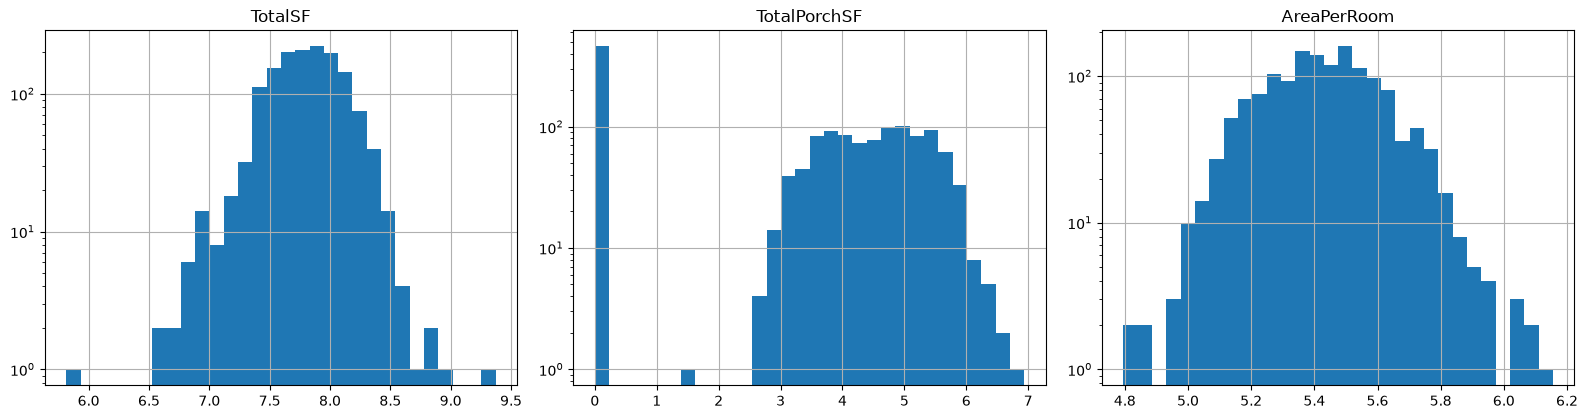

In [18]:
numeric_kept = ["TotalSF", "TotalPorchSF", "AreaPerRoom"]
df[numeric_kept].hist(bins=30, figsize=(16, 8), layout=(2, 3), log=True)
plt.tight_layout()
plt.show()

## 10. Huấn luyện mô hình bằng FLAML AutoML
Dùng automl để tìm mô hình và hyperparameter một cách tối giản. Lần này huấn luyện trên toàn bộ dữ liệu train, không chia 80/20 nữa.

In [19]:
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

In [20]:
automl = AutoML()

automl.fit(
    X_train=X,
    y_train=y,
    time_budget=120,
    metric="rmse",
    task="regression",
    seed=42,
    verbose=3
)

[flaml.automl.logger: 10-15 00:18:24] {2470} INFO - task = regression
[flaml.automl.logger: 10-15 00:18:24] {2481} INFO - Evaluation method: cv
[flaml.automl.logger: 10-15 00:18:24] {2584} INFO - Minimizing error metric: rmse
[flaml.automl.logger: 10-15 00:18:24] {2701} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd']
[flaml.automl.logger: 10-15 00:18:24] {3006} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 10-15 00:18:24] {3141} INFO - Estimated sufficient time budget=961s. Estimated necessary time budget=7s.
[flaml.automl.logger: 10-15 00:18:24] {3192} INFO -  at 0.1s,	estimator lgbm's best error=3.1302e-01,	best estimator lgbm's best error=3.1302e-01
[flaml.automl.logger: 10-15 00:18:24] {3006} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 10-15 00:18:24] {3192} INFO -  at 0.2s,	estimator lgbm's best error=3.1302e-01,	best estimator lgbm's best error=3.1302e-01
[flaml.automl.logger: 10-15 00:

In [21]:
print("Thuật toán tốt nhất:", automl.best_estimator)

Thuật toán tốt nhất: lgbm


## 11. Làm sạch dữ liệu test
Làm lại các bước ở trên cho test.csv. Median và giá trị phổ biến nhất lấy từ train, không tính lại trên test.

In [22]:
test_raw = pd.read_csv("../data/raw/test.csv", keep_default_na=False, na_values=na_values)
test_ids = test_raw["Id"]
test_df = test_raw.drop("Id", axis="columns")
test_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,20,RH,80,11622,Pave,NA,Reg,Lvl,AllPub,Inside,...,120,0,NA,MnPrv,NA,0,6,2010,WD,Normal
1,20,RL,81,14267,Pave,NA,IR1,Lvl,AllPub,Corner,...,0,0,NA,NA,Gar2,12500,6,2010,WD,Normal
2,60,RL,74,13830,Pave,NA,IR1,Lvl,AllPub,Inside,...,0,0,NA,MnPrv,NA,0,3,2010,WD,Normal
3,60,RL,78,9978,Pave,NA,IR1,Lvl,AllPub,Inside,...,0,0,NA,NA,NA,0,6,2010,WD,Normal
4,120,RL,43,5005,Pave,NA,IR1,HLS,AllPub,Inside,...,144,0,NA,NA,NA,0,1,2010,WD,Normal


Test có thêm vài cột số bị NA lẫn vào (tầng hầm, gara) nên cũng ép thành số. Ô trống của các cột này nghĩa là không có, điền 0.

In [23]:
test_df["MasVnrType"] = test_df["MasVnrType"].replace("None", "NA")

test_numeric_like = numeric_like + ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"]
test_df[test_numeric_like] = test_df[test_numeric_like].apply(pd.to_numeric, errors="coerce")

test_df[["LotFrontage", "MasVnrArea"]] = test_df[["LotFrontage", "MasVnrArea"]].fillna(medians)
test_df["GarageYrBlt"] = test_df["GarageYrBlt"].fillna(test_df["YearBuilt"]).astype(int)
test_df[test_numeric_like] = test_df[test_numeric_like].fillna(0)

Các cột chữ còn thiếu (KitchenQual, Exterior1st, Exterior2nd) điền bằng giá trị phổ biến nhất của train.

In [24]:
modes = X.select_dtypes(exclude="number").mode().iloc[0]
test_df = test_df.fillna(modes)

Cũng log1p các cột liên tục như train (test không có SalePrice).

In [25]:
test_continuous_cols = [col for col in continuous_cols if col != "SalePrice"]
test_df[test_continuous_cols] = np.log1p(test_df[test_continuous_cols])

## 12. Tạo đặc trưng cho test

In [26]:
test_original = np.expm1(test_df[log_cols]).round()

test_df["TotalSF"] = np.log1p(test_original["TotalBsmtSF"] + test_original["1stFlrSF"] + test_original["2ndFlrSF"])
test_df["TotalPorchSF"] = np.log1p(test_original[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1))
test_df["TotalBath"] = test_df["FullBath"] + 0.5 * test_df["HalfBath"] + test_df["BsmtFullBath"] + 0.5 * test_df["BsmtHalfBath"]
test_df["AreaPerRoom"] = np.log1p(test_original["GrLivArea"] / test_df["TotRmsAbvGrd"])
test_df["LotCoverage"] = test_original["1stFlrSF"] / test_original["LotArea"]
test_df["HouseAge"] = test_df["YrSold"] - test_df["YearBuilt"]
test_df["RemodAge"] = test_df["YrSold"] - test_df["YearRemodAdd"]
test_df["IsRemodeled"] = (test_df["YearRemodAdd"] != test_df["YearBuilt"]).astype(int)

test_df["HasEnclosedPorch"] = (test_df["EnclosedPorch"] > 0).astype(int)
test_df["HasScreenPorch"] = (test_df["ScreenPorch"] > 0).astype(int)
test_df["HasWoodDeck"] = (test_df["WoodDeckSF"] > 0).astype(int)

Bỏ các cột như train và sắp xếp cột đúng thứ tự lúc huấn luyện. Kiểm tra còn thiếu dữ liệu không.

In [27]:
test_df = test_df.drop(columns=drop_cols)
test_df = test_df[X.columns]
test_df.isna().sum().sum()

np.int64(0)

## 13. Dự đoán và xuất kết quả
SalePrice đang ở dạng log1p nên dùng `expm1` để đưa về giá thật. Mỗi lần chạy xuất ra một file mới theo ngày giờ, không ghi đè.

In [28]:
pred = np.expm1(automl.predict(test_df))
submission = pd.DataFrame({"Id": test_ids, "SalePrice": pred})

os.makedirs("../data/results", exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
submission.to_csv(f"../data/results/submission_{timestamp}.csv", index=False)
submission.head()

,Id,SalePrice
0,1461,125495.120454
1,1462,158949.777020
2,1463,185766.797676
3,1464,193805.470339
4,1465,183270.115902
